In [1]:
import keras
from keras import layers
from keras.datasets import mnist
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# b. Access the dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()
# Normalize data
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
# Convert 28x28 images into 784 values
x_train = x_train.reshape((len(x_train), 784))
x_test = x_test.reshape((len(x_test), 784))
print("Training data:", x_train.shape)
print("Testing data :", x_test.shape)

Training data: (60000, 784)
Testing data : (10000, 784)


In [27]:
from tensorflow import keras
from tensorflow.keras import layers

# Encoder - converts input into latent representation
encoding_dim = 32
input_img = keras.Input(shape=(784,))
encoded = layers.Dense(128, activation="relu")(input_img)
encoded = layers.Dense(encoding_dim, activation="relu")(encoded)
#Create encoder model
encoder = keras.Model(input_img, encoded, name="encoder")
encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)           │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 32)                  │           4,128 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 104,608 (408.62 KB)

 Trainable params: 104,608 (408.62 KB)

 Non-trainable params: 0 (0.00 B)

In [25]:
# d. Decoder - converts latent representation back to original input

decoded = layers.Dense(
128, activation="relu"
)(encoded)
decoded = layers.Dense(
784, activation="sigmoid"
)(decoded)
# Create Autoencoder
autoencoder = keras.Model(input_img, decoded)

In [28]:
# e. Compile model

autoencoder.compile(
optimizer="adam",
loss="binary_crossentropy",
metrics=["accuracy"]
)
autoencoder.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)           │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 32)                  │           4,128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 128)                 │           4,224 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 784)                 │         101,136 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

In [29]:
# Train the Autoencoder

autoencoder.fit(
x_train,
x_train,
epochs=10,
batch_size=256,
shuffle=True,
validation_data=(x_test, x_test)
)

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - accuracy: 0.0093 - loss: 0.2349 - val_accuracy: 0.0089 - val_loss: 0.1525
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - accuracy: 0.0102 - loss: 0.1355 - val_accuracy: 0.0102 - val_loss: 0.1212
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.0094 - loss: 0.1171 - val_accuracy: 0.0103 - val_loss: 0.1110
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.0103 - loss: 0.1089 - val_accuracy: 0.0118 - val_loss: 0.1050
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.0102 - loss: 0.1041 - val_accuracy: 0.0122 - val_loss: 0.1010
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - accuracy: 0.0115 - loss: 0.1011 - val_accuracy: 0.0116 - val_loss: 0.0985
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.0116 - loss: 0.0991 - val_accuracy: 0.0132 - val_loss: 0.0970
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - accuracy: 0.0123 - loss: 0.0974 - val_accu

In [30]:
# ANOMALY DETECTION
# Reconstruct test images
decoded_imgs = autoencoder.predict(x_test)

# Calculate reconstruction error
error = np.mean(
    np.square(x_test - decoded_imgs),
    axis=tuple(range(1, x_test.ndim))
)
# Set threshold at the 95th percentile
threshold = np.percentile(error, 95)
print("Anomaly Threshold:", threshold)
# Detect anomalies
anomalies = error > threshold
print("Number of anomalies:", np.sum(anomalies))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Anomaly Threshold: 0.021098344
Number of anomalies: 500


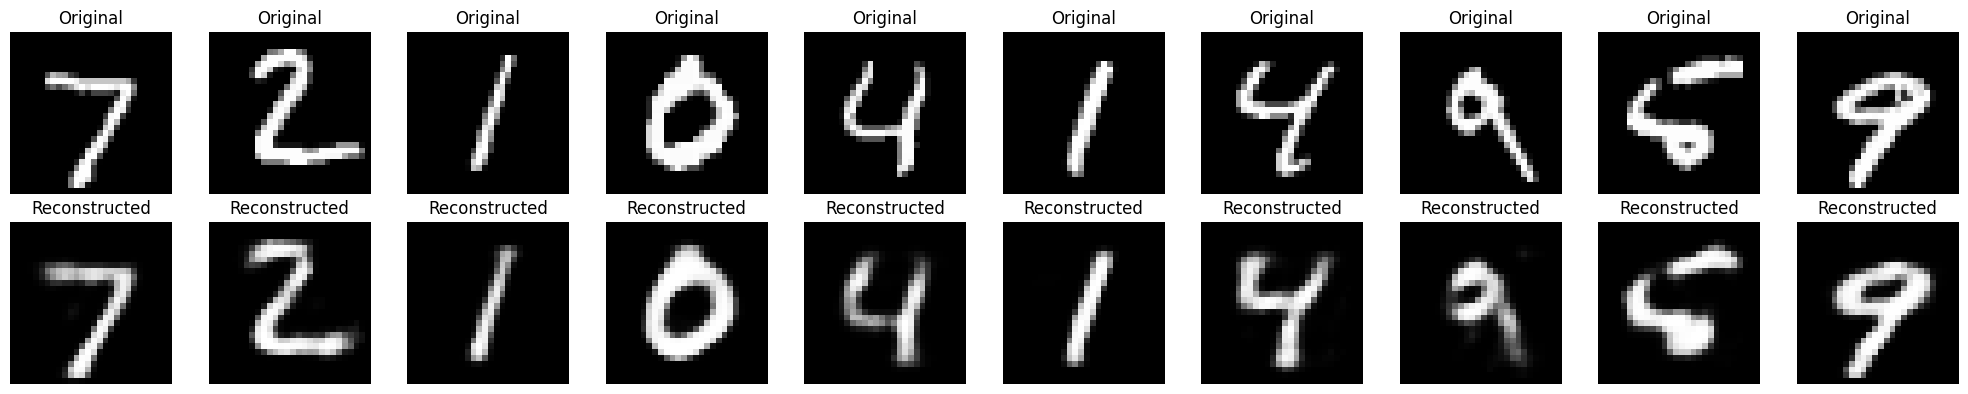

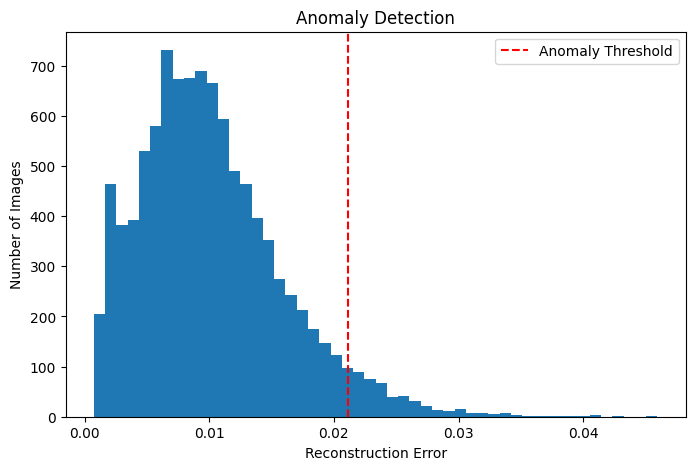

In [31]:
# Display original and reconstructed images
n = 10
plt.figure(figsize=(20, 4))
for i in range(n):
# Original image
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.title("Original")
    plt.axis("off")
# Reconstructed image
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(decoded_imgs[i].reshape(28, 28), cmap="gray")
    plt.title("Reconstructed")
    plt.axis("off")
plt.tight_layout()
plt.show()

# Plot reconstruction error
plt.figure(figsize=(8, 5))
plt.hist(error, bins=50)
plt.axvline(
    threshold,
    color="red",
    linestyle="--",
    label="Anomaly Threshold"
)
plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Images")
plt.title("Anomaly Detection")
plt.legend()
plt.show()